# Lab03
**Isabela Torres-Septien Uribe**

**Andrea Santoyo Vega**

**Abdon Islas Leon**

In [17]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Ajusta REPO_ROOT si el notebook NO está en la raíz del repo
REPO_ROOT = os.path.abspath(".")
os.chdir(REPO_ROOT)           # para que 'artifacts/' resuelva bien
sys.path.insert(0, REPO_ROOT)

from data import download_data
from cointegration import integration_order, screening, rolling_johansen
from strategy import vecm

plt.rcParams["figure.figsize"] = (10, 4)
print("Repo:", REPO_ROOT)

Repo: c:\Users\Isabela\Documents\Iteso\9no Semestre\Trading\Lab03_MyST_Isabela-Andrea-Abdon-repository


In [18]:
download_data.main()

=== Huecos / cobertura ===
ticker primer_dato ultimo_dato  n_obs  n_faltantes
   AMT  2015-10-01  2026-09-30   2765            0
   CCI  2015-10-01  2026-09-30   2765            0
  SBAC  2015-10-01  2026-09-30   2765            0
    VZ  2015-10-01  2026-09-30   2765            0
     T  2015-10-01  2026-09-30   2765            0
  TMUS  2015-10-01  2026-09-30   2765            0

=== Saltos detectados ===
ticker      fecha  ret_%     z                                                    evento
  TMUS 2020-02-11  11.14   6.6                                                          
     T 2020-03-12  -9.70  -6.6                                                          
  TMUS 2020-03-12 -11.89  -7.1                                                          
  TMUS 2020-03-13  10.65   6.3                                                          
     T 2020-03-13   9.55   6.5                                                          
  TMUS 2020-03-16 -10.95  -6.5                         

In [19]:
# Saltos detectados (eventos estructurales)
pd.read_csv("artifacts/data_jumps.csv")

,ticker,fecha,ret_%,z,evento
0,TMUS,2020-02-11,11.14,6.6,NaN
1,T,2020-03-12,-9.70,-6.6,NaN
2,TMUS,2020-03-12,-11.89,-7.1,NaN
3,TMUS,2020-03-13,10.65,6.3,NaN
4,T,2020-03-13,9.55,6.5,NaN
5,TMUS,2020-03-16,-10.95,-6.5,NaN
6,AMT,2020-03-16,-16.44,-10.1,NaN
7,CCI,2020-03-16,-13.27,-8.2,NaN
8,AMT,2020-03-17,11.53,7.0,NaN
9,T,2020-03-20,-9.07,-6.2,NaN


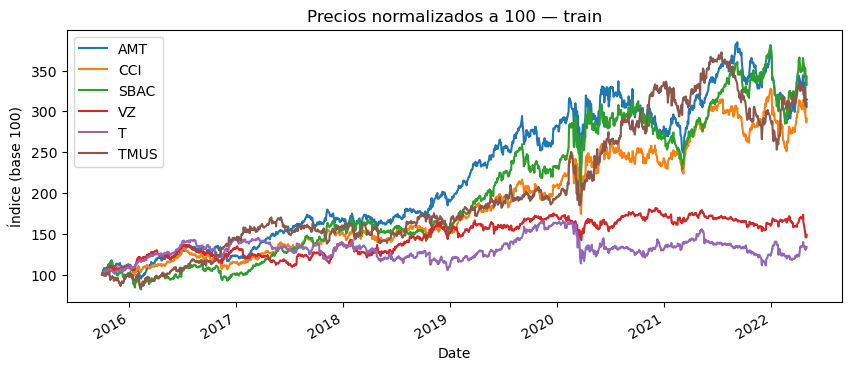

In [20]:
# Precios normalizados a 100 (train) para ver co-movimiento
tr = pd.read_csv("artifacts/prices_train.csv", index_col=0, parse_dates=True)
(tr / tr.iloc[0] * 100).plot(title="Precios normalizados a 100 — train")
plt.ylabel("Índice (base 100)"); plt.show()

## Integración

In [21]:
integration_order.main()
pd.read_csv("artifacts/integration_order.csv")

ticker  ADF_nivel_p  ADF_diff_p  KPSS_nivel_p   orden
   AMT       0.7223         0.0          0.01    I(1)
   CCI       0.8722         0.0          0.01    I(1)
  SBAC       0.8905         0.0          0.01    I(1)
    VZ       0.1884         0.0          0.01    I(1)
     T       0.0161         0.0          0.01 revisar
  TMUS       0.7938         0.0          0.01    I(1)


,ticker,ADF_nivel_p,ADF_diff_p,KPSS_nivel_p,orden
0,AMT,0.7223,0.0,0.01,I(1)
1,CCI,0.8722,0.0,0.01,I(1)
2,SBAC,0.8905,0.0,0.01,I(1)
3,VZ,0.1884,0.0,0.01,I(1)
4,T,0.0161,0.0,0.01,revisar
5,TMUS,0.7938,0.0,0.01,I(1)


## Embudo de cointegración
Correlación móvil 126d → Engle-Granger (15 pares, ambos sentidos) →
Johansen (57 grupos) → ADF del spread → vida media.

In [22]:
screening.main()

=== Prefiltro informativo (15 pares) ===
      par  corr_movil_mediana  pasa_corr  EG_p_AB  EG_p_BA  pasa_EG
  AMT-CCI              0.7623       True   0.6347   0.6200    False
 AMT-SBAC              0.7532       True   0.0676   0.1052    False
   AMT-VZ              0.2518      False   0.1044   0.0401     True
    AMT-T              0.1561      False   0.8730   0.0641    False
 AMT-TMUS              0.1747      False   0.2984   0.3198    False
 CCI-SBAC              0.7419       True   0.0520   0.0664    False
   CCI-VZ              0.2288      False   0.3819   0.1073    False
    CCI-T              0.1816      False   0.9328   0.0346     True
 CCI-TMUS              0.1939      False   0.0770   0.1025    False
  SBAC-VZ              0.1879      False   0.3459   0.0715    False
   SBAC-T              0.1369      False   0.9491   0.0593    False
SBAC-TMUS              0.2362      False   0.3122   0.2705    False
     VZ-T              0.6485      False   0.6728   0.1224    False
  VZ-TM

,sub_muestra,n_obs,ADF_spread_p,estacionario,vida_media
0,sub_train,995,0.0136,True,42.8
1,sub_test,332,0.6147,False,20.6
2,sub_val,332,0.8497,False,98.8


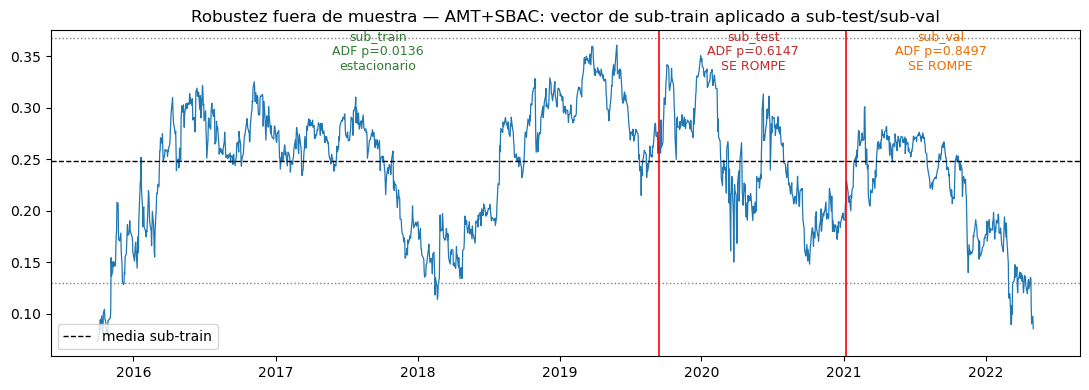

In [23]:
# --- Robustez fuera de muestra: vector de sub-train congelado -> ¿se rompe en sub-test? ---
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from cointegration.robustez_oos import sub_split, evaluar_spread
from cointegration.screening import normalizar_vector

chosen = json.load(open("artifacts/chosen_group.json"))
cols = chosen["grupo"].split("+")
logpx = np.log(pd.read_csv("artifacts/prices_train.csv", index_col=0,
                           parse_dates=True)[cols]).dropna()

partes = sub_split(logpx)                       # sub_train / sub_test / sub_val
jo = coint_johansen(partes["sub_train"], det_order=0, k_ar_diff=1)
w, leg = normalizar_vector(jo.evec[:, 0])       # vector estimado SOLO en sub-train

# Tabla veredicto
tabla = pd.DataFrame([{"sub_muestra": k, **evaluar_spread(v.values @ w)}
                      for k, v in partes.items()])
display(tabla)

# Spread continuo + media/bandas de sub-train
spread = pd.Series(logpx.values @ w, index=logpx.index)
base = partes["sub_train"].values @ w
mu, sd = base.mean(), base.std()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(spread.index, spread.values, lw=0.9, color="#1f77b4")
ax.axhline(mu, ls="--", c="k", lw=1, label="media sub-train")
ax.axhline(mu + 2*sd, ls=":", c="gray", lw=1)
ax.axhline(mu - 2*sd, ls=":", c="gray", lw=1)

for b in (partes["sub_train"].index[-1], partes["sub_test"].index[-1]):
    ax.axvline(b, c="red", lw=1.2)

colores = {"sub_train": "#2e7d32", "sub_test": "#c62828", "sub_val": "#ef6c00"}
for _, r in tabla.iterrows():
    seg = partes[r["sub_muestra"]]
    etiqueta = "estacionario" if r["estacionario"] else "SE ROMPE"
    ax.text(seg.index[len(seg)//2], ax.get_ylim()[1],
            f"{r['sub_muestra']}\nADF p={r['ADF_spread_p']}\n{etiqueta}",
            ha="center", va="top", fontsize=9, color=colores[r["sub_muestra"]])

ax.set_title(f"Robustez fuera de muestra — {chosen['grupo']}: "
             f"vector de sub-train aplicado a sub-test/sub-val")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

In [24]:
# Engle-Granger en los 15 pares
pd.read_csv("artifacts/engle_granger_pairs.csv")

,par,corr_movil_mediana,pasa_corr,EG_p_AB,EG_p_BA,pasa_EG
0,AMT-CCI,0.7623,True,0.6347,0.6200,False
1,AMT-SBAC,0.7532,True,0.0676,0.1052,False
2,AMT-VZ,0.2518,False,0.1044,0.0401,True
3,AMT-T,0.1561,False,0.8730,0.0641,False
4,AMT-TMUS,0.1747,False,0.2984,0.3198,False
5,CCI-SBAC,0.7419,True,0.0520,0.0664,False
6,CCI-VZ,0.2288,False,0.3819,0.1073,False
7,CCI-T,0.1816,False,0.9328,0.0346,True
8,CCI-TMUS,0.1939,False,0.0770,0.1025,False
9,SBAC-VZ,0.1879,False,0.3459,0.0715,False


In [25]:
import itertools, numpy as np, pandas as pd
tr = pd.read_csv("artifacts/prices_train.csv", index_col=0, parse_dates=True)
log = np.log(tr)
filas = []
for a, b in itertools.combinations(log.columns, 2):
    rc = log[a].rolling(126).corr(log[b]).mean()
    filas.append({"par": f"{a}-{b}", "corr_movil_126d": round(rc, 3)})
pd.DataFrame(filas).sort_values("corr_movil_126d", ascending=False)

,par,corr_movil_126d
0,AMT-CCI,0.808
1,AMT-SBAC,0.778
5,CCI-SBAC,0.732
12,VZ-T,0.540
14,T-TMUS,0.378
8,CCI-TMUS,0.354
13,VZ-TMUS,0.300
4,AMT-TMUS,0.283
11,SBAC-TMUS,0.270
6,CCI-VZ,0.247


In [26]:
# Resumen: cuántos grupos cayeron en cada etapa del embudo
res = pd.read_csv("artifacts/screening_all_groups.csv")
res["etapa_caida"].value_counts()

etapa_caida
johansen    54
PASA         3
Name: count, dtype: int64

In [27]:
# Falsos positivos esperados (N_tests * 0.05)
pd.read_csv("artifacts/false_positives.csv")

,prueba,n_tests,alpha,FP_esperados
0,Engle-Granger,30,0.05,1.50
1,Johansen,57,0.05,2.85


In [28]:
# Grupo elegido (el más reversivo que pasó el embudo completo)
chosen = json.load(open("artifacts/chosen_group.json"))
print("Grupo elegido:", chosen["grupo"])
print("Vector normalizado:", chosen["vector"])

Grupo elegido: AMT+SBAC
Vector normalizado: [1.0, -0.8631]


## VECM

In [29]:
vecm.main()

=== Beta (vector de cointegracion) ===
ticker    beta
   AMT  1.0000
  SBAC -0.8631

=== Alpha (velocidad de ajuste) ===
ticker   alpha   pval
   AMT -0.0017 0.7926
  SBAC  0.0163 0.0221

>>> Corrige principalmente el desequilibrio: SBAC (alpha mas grande en magnitud y significativo si pval<0.05)


In [30]:
beta = pd.read_csv("artifacts/vecm_beta.csv")
alpha = pd.read_csv("artifacts/vecm_alpha.csv")
display(beta); display(alpha)

,ticker,beta
0,AMT,1.0000
1,SBAC,-0.8631


,ticker,alpha,pval
0,AMT,-0.0017,0.7926
1,SBAC,0.0163,0.0221


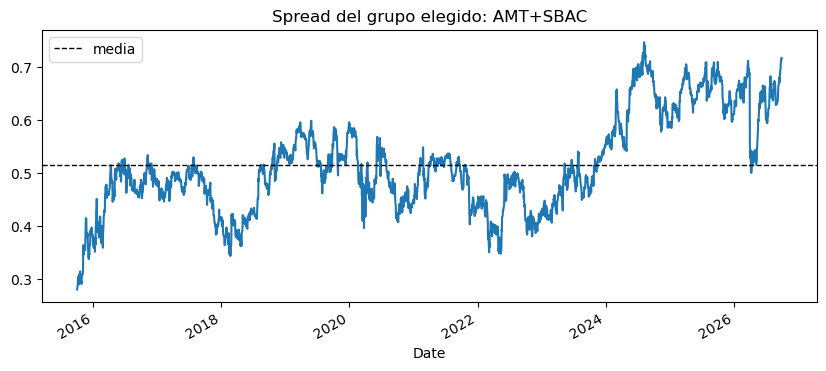

In [31]:
# Spread del grupo elegido sobre toda la muestra
cols = chosen["grupo"].split("+")
w = np.array(chosen["vector"])
full = pd.read_csv("artifacts/prices_full.csv", index_col=0, parse_dates=True)
spread = (np.log(full[cols]) @ w).dropna()
spread.plot(title=f"Spread del grupo elegido: {chosen['grupo']}")
plt.axhline(spread.mean(), ls="--", c="k", lw=1, label="media")
plt.legend(); plt.show()

## Prueba Johansen

In [32]:
rolling_johansen.main()

            AMT    SBAC
fecha                  
2022-03-31  1.0  4.2351
2022-04-07  1.0  1.2880
2022-04-14  1.0  3.4548
2022-04-22  1.0  1.5173
2022-04-29  1.0  5.2278

Guardado: artifacts/rolling_eigenvector.csv  (282 ventanas)


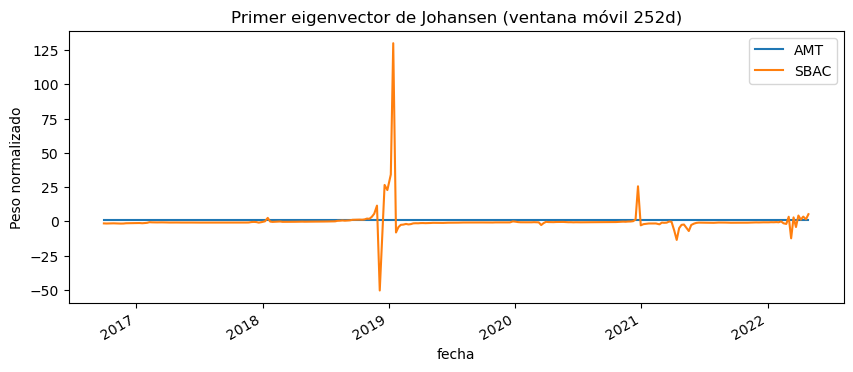

In [33]:
roll = pd.read_csv("artifacts/rolling_eigenvector.csv", index_col=0, parse_dates=True)
roll.plot(title="Primer eigenvector de Johansen (ventana móvil 252d)")
plt.ylabel("Peso normalizado"); plt.show()